In [4]:
# Mini-Courier Planner

In [ ]:
import csv

# Load parcel data
def load_parcels(filename):
    parcels = []


In [ ]:

    with open(filename, "r") as file:
        reader = csv.DictReader(file)

        for row in reader:
            row["weight"] = int(row["weight"])
            row["value"] = int(row["value"])
            row["deadline"] = int(row["deadline"])
            row["priority"] = int(row["priority"])
            parcels.append(row)

    return parcels


# Sort parcels by priority
def sort_parcels(parcels):
    return sorted(parcels, key=lambda x: x["priority"], reverse=True)


# Main program
parcels = load_parcels("datasets/parcels.csv")

sorted_parcels = sort_parcels(parcels)

print("=== Parcel Priority List ===")

for parcel in sorted_parcels:
    print(
        parcel["parcel_id"],
        "Weight:", parcel["weight"],
        "Value:", parcel["value"],
        "Deadline:", parcel["deadline"],
        "Priority:", parcel["priority"]
    )
    # Dynamic Programming - 0/1 Knapsack
def knapsack(parcels, capacity):
    n = len(parcels)

    dp = [[0 for _ in range(capacity + 1)] for _ in range(n + 1)]

    for i in range(1, n + 1):
        weight = parcels[i - 1]["weight"]
        value = parcels[i - 1]["value"]

        for w in range(1, capacity + 1):

            if weight <= w:
                dp[i][w] = max(
                    dp[i - 1][w],
                    value + dp[i - 1][w - weight]
                )
            else:
                dp[i][w] = dp[i - 1][w]

    selected = []
    w = capacity

    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            selected.append(parcels[i - 1])
            w -= parcels[i - 1]["weight"]

    selected.reverse()

    return selected, dp[n][capacity]


# Select parcels for one delivery trip
capacity = 15

selected_parcels, maximum_value = knapsack(parcels, capacity)

print("\n=== Optimal Packing Plan ===")
print("Van Capacity:", capacity, "kg")

for parcel in selected_parcels:
    print(
        parcel["parcel_id"],
        "Weight:", parcel["weight"],
        "Value:", parcel["value"]
    )

print("Maximum Value:", maximum_value)
# Dijkstra's Shortest Path Algorithm
import heapq


def load_routes(filename):
    graph = {}

    with open(filename, "r") as file:
        reader = csv.DictReader(file)

        for row in reader:
            source = row["source"]
            destination = row["destination"]
            distance = int(row["distance"])

            if source not in graph:
                graph[source] = []

            if destination not in graph:
                graph[destination] = []

            graph[source].append((destination, distance))
            graph[destination].append((source, distance))

    return graph


def dijkstra(graph, start):
    distances = {node: float("inf") for node in graph}
    distances[start] = 0

    priority_queue = [(0, start)]

    while priority_queue:
        current_distance, current_node = heapq.heappop(priority_queue)

        if current_distance > distances[current_node]:
            continue

        for neighbor, weight in graph[current_node]:
            new_distance = current_distance + weight

            if new_distance < distances[neighbor]:
                distances[neighbor] = new_distance
                heapq.heappush(priority_queue, (new_distance, neighbor))

    return distances


# Load route graph
graph = load_routes("datasets/routes.csv")

# Find shortest paths from Warehouse
shortest_paths = dijkstra(graph, "Warehouse")

print("\n=== Shortest Paths from Warehouse ===")

for location, distance in shortest_paths.items():
    print(location, ":", distance)
    # Nearest Neighbor TSP Approximation
def nearest_neighbor_route(graph, start):
    route = [start]
    unvisited = set(graph.keys())
    unvisited.remove(start)

    current = start
    total_distance = 0

    while unvisited:

        nearest = None
        shortest_distance = float("inf")

        for neighbor, distance in graph[current]:

            if neighbor in unvisited and distance < shortest_distance:
                nearest = neighbor
                shortest_distance = distance

        if nearest is None:
            break

        route.append(nearest)
        total_distance += shortest_distance

        unvisited.remove(nearest)
        current = nearest

    # Return to warehouse
    for neighbor, distance in graph[current]:
        if neighbor == start:
            total_distance += distance
            route.append(start)
            break

    return route, total_distance


# Create delivery route
delivery_route, route_distance = nearest_neighbor_route(
    graph, "Warehouse"
)

print("\n=== Delivery Route ===")
print(" -> ".join(delivery_route))
print("Total Route Distance:", route_distance)
# Runtime Testing
import time

start_time = time.perf_counter()

load_parcels("datasets/parcels.csv")
load_routes("datasets/routes.csv")

end_time = time.perf_counter()

runtime = end_time - start_time

print("\n=== Runtime Performance ===")
print("Data Loading Runtime:", runtime, "seconds")

=== Runtime Comparison ===
Input Size: 10 | Sorting: 4.0099999750964344e-05 | Knapsack: 7.650000043213367e-05
Input Size: 20 | Sorting: 6.999995093792677e-06 | Knapsack: 8.58000130392611e-05
Input Size: 50 | Sorting: 1.2299991794861853e-05 | Knapsack: 0.00041680000140331686
Input Size: 100 | Sorting: 3.330000618007034e-05 | Knapsack: 0.000498699999297969


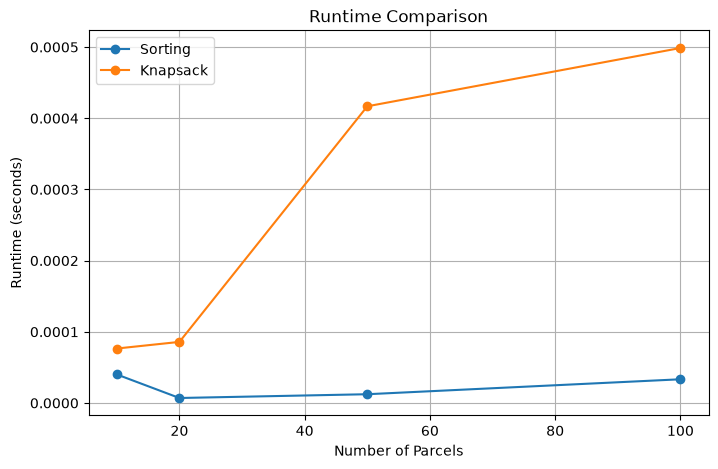

In [6]:
import time
import matplotlib.pyplot as plt

sizes = [10, 20, 50, 100]
sorting_times = []
knapsack_times = []

for size in sizes:

    test_parcels = parcels * ((size // len(parcels)) + 1)
    test_parcels = test_parcels[:size]

    # Sorting runtime
    start = time.perf_counter()
    sort_parcels(test_parcels)
    end = time.perf_counter()
    sorting_times.append(end - start)

    # Knapsack runtime
    start = time.perf_counter()
    knapsack(test_parcels, 15)
    end = time.perf_counter()
    knapsack_times.append(end - start)


print("=== Runtime Comparison ===")

for i in range(len(sizes)):
    print(
        "Input Size:", sizes[i],
        "| Sorting:", sorting_times[i],
        "| Knapsack:", knapsack_times[i]
    )


plt.figure(figsize=(8, 5))

plt.plot(sizes, sorting_times, marker="o", label="Sorting")
plt.plot(sizes, knapsack_times, marker="o", label="Knapsack")

plt.xlabel("Number of Parcels")
plt.ylabel("Runtime (seconds)")
plt.title("Runtime Comparison")
plt.legend()
plt.grid(True)

plt.savefig("images/runtime_comparison.png")
plt.show()